# A non-differentiable cost function for the zeroth-order solvers

The comfort-weighted example in `Experiments.ipynb` uses
`T(alpha) + omega * RMS(a_x)`, which is smooth: an optimal-control solver could
minimise it directly, given a formulation that exposes the objective.

Here the penalty is an **indicator integral**: the time spent close to the
friction limit,

$$t_{\mathrm{lim}}(\alpha)\;=\;\int \mathbb{1}\!\left[\,u(s;\alpha) > u_{\star}\,\right]\,dt,
\qquad
u \;=\; \left(\frac{|a_x|}{a_{\max}}\right)^{e} + \left(\frac{|a_y|}{a_{\max}}\right)^{e},$$

and the cost is $C_\lambda(\alpha) = T(\alpha) + \lambda\,t_{\mathrm{lim}}(\alpha)$.

Two properties matter.

**It is not differentiable.** The integrand is an indicator, so on the solver's
grid $t_{\mathrm{lim}}$ is a sum of step functions: piecewise constant in
$\alpha$, zero gradient almost everywhere, undefined on the jumps. In the
continuum limit it is Lipschitz but not $C^1$, kinked wherever the profile is
tangent to the threshold. An optimal-control formulation needs either integer
variables or a smooth surrogate such as a sigmoid; neither is what the solver is
handed here.

**It genuinely conflicts with lap time.** A faster raceline rides closer to the
envelope for longer, so $t_{\mathrm{lim}}$ *rises* as $T$ falls. 

In [ ]:
# ===========================================================================
# 1. Setup -- identical vehicle, track and hyper-parameters to Experiments.ipynb
#    so the lap times here are directly comparable with Tables I and III.
# ===========================================================================
import os
import time

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9,
    "axes.titlesize": 9, "legend.fontsize": 8, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "figure.dpi": 150, "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

from OptiLine import solvers
from OptiLine.utils import (calc_splines, create_raceline, calc_head_curv_an,
                            import_veh_dyn_info, seg_bounds, subsample_reftrack)
from OptiLine.KinematicProfs import (calc_vel_profile, calc_ax_profile,
                                     calc_t_profile)

MAPS_DIR = "maps"
GGV_PATH = os.path.join("input_files", "ggv.csv")
AX_MAX_PATH = os.path.join("input_files", "ax_max_machines.csv")
FIG_DIR = "paper_figs"
os.makedirs(FIG_DIR, exist_ok=True)

CIRCUIT = "Budapest"
TRACK = os.path.join(MAPS_DIR, CIRCUIT, f"{CIRCUIT}_centerline.csv")

VEH = dict(v_max=22.88, m_veh=1000.0, drag_coeff=0.75,
           kappa_bound=0.5, w_veh=1.0, fw=3, dyn_model_exp=1.5)

# An indicator integral depends on the grid it is accumulated on, so the cost
# and the reported metric use ONE discretisation: the same 0.25 m step that
# every other table in the paper reports on. This costs about 3x per evaluation
# relative to a 1.0 m step (24 ms against 7 ms), which is why a full sweep takes
# a few hours.
SI = 0.25
N_INTERP_CON = 2
SEG_LO, SEG_HI = 0.7, 1.8

# Budapest blackbox hyper-parameters, as tuned in Experiments.ipynb (MAP_HYP),
# with ONE change: mu is raised from 1e-5 to 1e-3.
#
# Why. The penalty is an indicator integral, so when a grid cell crosses the
# threshold t_lim jumps by one cell, about 23 ms. The difference quotient for
# that direction is 0.023/mu, which at mu = 1e-5 is ~2300 against a median of
# 4.8 -- a 400x tail. Averaged over t = 12 directions, roughly one iteration in
# nine is dominated by such a spike; 
BBA = dict(mu=1e-3, h=3e-4, t=12, grad_type='noth',
           iterations=200, sigma=0.03, n_jobs=12)

# the stochastic solver is unseeded, so every reported result is a mean over runs
N_REPEATS = 3


def agg(vals):
    """(mean, sample std) of a list of scalars."""
    a = np.asarray(vals, dtype=float)
    return float(a.mean()), (float(a.std(ddof=1)) if a.size > 1 else 0.0)


def median_idx(vals):
    """Index of the median run; used wherever one representative curve is drawn."""
    a = np.asarray(vals, dtype=float)
    return int(np.argsort(a)[(a.size - 1) // 2])


def pm(mean, sd, p=2):
    """LaTeX cell 'mean +- sd'."""
    return f"${mean:.{p}f} \\pm {sd:.{p}f}$"


reftrack = subsample_reftrack(
    np.loadtxt(TRACK, comments='#', delimiter=',')[:, :4], step=4, mode='arc')
ggv, ax_max = import_veh_dyn_info(GGV_PATH, AX_MAX_PATH)

_, _, _lengths = seg_bounds(reftrack, lo=SEG_LO, hi=SEG_HI)
_cx, _cy, _M, _nv = calc_splines(
    path=np.vstack((reftrack[:, :2], reftrack[0, :2])),
    el_lengths=_lengths, use_dist_scaling=True)

print(f"{CIRCUIT}: {len(reftrack)} reference nodes, "
      f"corridor {reftrack[:, 2].min():.2f}-{reftrack[:, 2].max():.2f} m")

Budapest: 219 reference nodes, corridor 1.10-1.10 m


In [11]:
# ===========================================================================
# 2. The non-differentiable metric
# ===========================================================================
U_STAR = 0.97       # fraction of the envelope radius counted as "at the limit".
                    # Chosen by measurement: across 0.90-1.00 it gives the widest
                    # spread over candidate racelines (5.6 s) and the strongest
                    # conflict with lap time. At 1.00 the conflict reverses sign.
A_MAX = 12.0        # [m/s^2] the envelope radius, as in ggv.csv

_ggv_cache = {}


def profile(alpha, si=SI):
    """Kinematic profiles for a lateral-shift vector. Returns (s, vx, ax, t, dt).

    This is the same forward--backward chain the rest of the package uses; it is
    inlined here so the cost can be evaluated without constructing a solver.
    """
    _, _, cx, cy, si_idx, tv, _, _, el = create_raceline(
        refline=reftrack[:, :2], normvectors=_nv, alpha=alpha, stepsize_interp=si)
    _, kappa = calc_head_curv_an(coeffs_x=cx, coeffs_y=cy, ind_spls=si_idx, t_spls=tv)
    n = kappa.size
    if n not in _ggv_cache:
        _ggv_cache[n] = np.repeat(np.expand_dims(ggv, 0), n, 0)
    vx = calc_vel_profile(
        ggv=ggv, ax_max_machines=ax_max, v_max=VEH['v_max'], kappa=kappa,
        el_lengths=el, closed=True, filt_window=VEH['fw'],
        dyn_model_exp=VEH['dyn_model_exp'], drag_coeff=VEH['drag_coeff'],
        m_veh=VEH['m_veh'], p_ggv=_ggv_cache[n])
    ax = calc_ax_profile(vx_profile=np.append(vx, vx[0]), el_lengths=el,
                         eq_length_output=False)
    t = calc_t_profile(vx_profile=vx, ax_profile=ax, el_lengths=el)
    s = np.concatenate(([0.0], np.cumsum(el)[:-1]))
    dt = np.diff(t)
    m = min(len(vx), len(kappa), len(ax), len(dt))
    ay = vx[:m] ** 2 * kappa[:m]
    e = VEH['dyn_model_exp']
    util = (np.abs(ax[:m]) / A_MAX) ** e + (np.abs(ay) / A_MAX) ** e
    return dict(s=s[:m], vx=vx[:m], ax=ax[:m], ay=ay, util=util,
                dt=dt[:m], laptime=float(t[-1]))


def t_limit(p, u_star=U_STAR):
    """Seconds with the combined acceleration above u_star of the envelope.

    What u measures. It is recomputed after the fact from differences of the
    returned velocity profile, whereas the forward--backward solver enforced the
    envelope with its own internal acceleration; the two agree only to a few per
    cent, and filt_window smooths vx after the envelope was applied. So u is the
    magnitude of the ACHIEVED combined acceleration relative to the envelope
    radius, not a tyre-utilisation factor, and u > 1 is not a violation.

    As a functional of alpha this is Lipschitz and non-differentiable: the
    integrand is an indicator, so the integral is continuous but kinked wherever
    the profile is tangent to the threshold. On the finite grid it resolves as
    ~1584 steps of about 23 ms, far finer than the smoothing radius mu, which is
    what keeps the zeroth-order estimator well scaled.
    """
    return float(p['dt'][p['util'] > u_star].sum())


def metrics(alpha, si=SI):
    """Everything reported for one solution."""
    p = profile(alpha, si=si)
    p['t_lim'] = t_limit(p)
    return p


def make_cost(lam):
    """C_lambda(alpha) = T(alpha) + lambda * t_lim(alpha)."""
    def cost(alpha):
        p = profile(alpha, si=SI)
        return p['laptime'] + lam * t_limit(p)
    return cost


def build_bba(cost_fn=None, init='mincurv', n_iter=None):
    return solvers.Blackbox_raceline(
        n_interp_con=N_INTERP_CON, reftrack=reftrack, ggv=ggv,
        ax_max_machines=ax_max, sfty=VEH['w_veh'] / 2, v_max=VEH['v_max'],
        si=SI, fw=VEH['fw'], m_veh=VEH['m_veh'],
        drag_coeff=VEH['drag_coeff'], dyn_model_exp=VEH['dyn_model_exp'],
        cost_fn=cost_fn, init=init, oracle='gaussian',
        mu=BBA['mu'], h=BBA['h'], t=BBA['t'], grad_type=BBA['grad_type'],
        iterations=n_iter if n_iter is not None else BBA['iterations'],
        kappa_bound=VEH['kappa_bound'], seed=None, n_jobs=BBA['n_jobs'])


# minimum-curvature reference: the warm start every run below begins from
_ref = build_bba(n_iter=1)
alpha_mc = _ref.alpha_0.copy()
mc = metrics(alpha_mc)
print(f"min-curvature reference: lap {mc['laptime']:.3f} s   "
      f"t_lim {mc['t_lim']:.3f} s   ({len(mc['dt'])} grid cells, "
      f"mean {1e3 * mc['dt'].mean():.1f} ms each)")

min-curvature reference: lap 36.375 s   t_lim 22.588 s   (1584 grid cells, mean 23.0 ms each)


Saved: paper_figs/fig_nondiff_indicator.pdf
  t_lim on the MC line: 22.588 s of 36.375 s (62.1% of the lap at the limit)
  grid: 1584 cells, mean 23.0 ms -> step height of one crossing
  along the slice t_lim spans 20.750-22.692 s in 300 distinct values


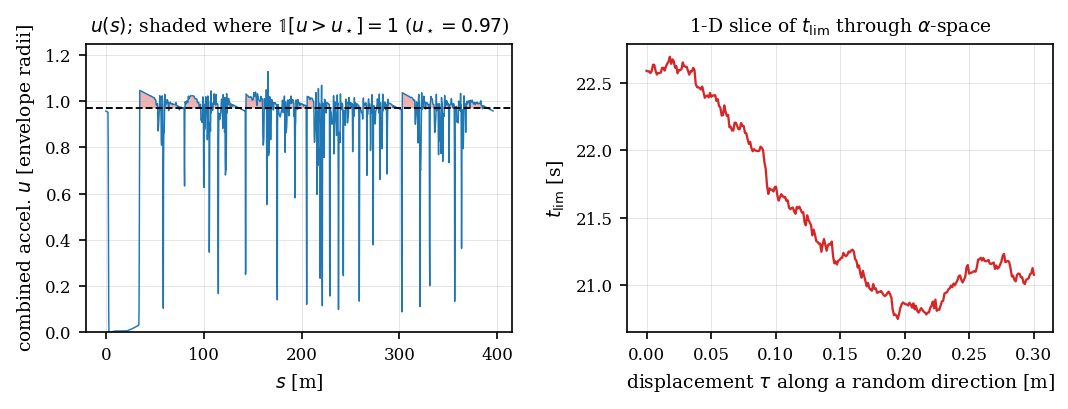

In [13]:
# ===========================================================================
# 3. Where the non-differentiability lives
#
# Left:  the integrand. Utilisation u(s) against the threshold u_star, with the
#        counted region shaded. The integrand is an indicator, so it jumps
#        between 0 and 1 at every crossing -- this is the discontinuity an
#        optimal-control transcription would have to smooth away or encode with
#        integer variables.
# Right: t_lim along a line in alpha-space. Formally a sum of 1584 step
#        functions, so piecewise constant with zero gradient almost everywhere;
#        in practice the steps are finer than 1e-6 m of displacement, which is
#        what lets a zeroth-order oracle estimate a descent direction at all.
# ===========================================================================
rng = np.random.default_rng(0)
u_dir = rng.normal(size=alpha_mc.size)
u_dir /= np.linalg.norm(u_dir)

fig, (axl, axr) = plt.subplots(1, 2, figsize=(7.2, 2.8))

_s, _u = mc['s'], mc['util']
axl.plot(_s, _u, color='tab:blue', lw=0.7)
axl.axhline(U_STAR, color='k', ls='--', lw=0.9)
axl.fill_between(_s, U_STAR, _u, where=(_u > U_STAR),
                 color='tab:red', alpha=0.35, lw=0, step=None)
axl.set_xlabel('$s$ [m]')
axl.set_ylabel(r'combined accel. $u$ [envelope radii]')
axl.set_ylim(0, 1.25)
axl.set_title(rf'$u(s)$; shaded where $\mathbb{{1}}[u>u_\star]=1$ ($u_\star={U_STAR:g}$)')
axl.grid(True, lw=0.3, alpha=0.5)

taus = np.linspace(0.0, 0.30, 300)
vals = np.array([t_limit(profile(alpha_mc + t_ * u_dir)) for t_ in taus])
axr.plot(taus, vals, color='tab:red', lw=1.1)
axr.set_xlabel(r'displacement $\tau$ along a random direction [m]')
axr.set_ylabel(r'$t_{\mathrm{lim}}$ [s]')
axr.set_title(r'1-D slice of $t_{\mathrm{lim}}$ through $\alpha$-space')
axr.grid(True, lw=0.3, alpha=0.5)

plt.tight_layout()
_f = os.path.join(FIG_DIR, 'fig_nondiff_indicator.pdf')
plt.savefig(_f)
print(f"Saved: {_f}")
print(f"  t_lim on the MC line: {mc['t_lim']:.3f} s of {mc['laptime']:.3f} s "
      f"({100 * mc['t_lim'] / mc['laptime']:.1f}% of the lap at the limit)")
print(f"  grid: {len(mc['dt'])} cells, mean {1e3 * mc['dt'].mean():.1f} ms "
      f"-> step height of one crossing")
print(f"  along the slice t_lim spans {vals.min():.3f}-{vals.max():.3f} s "
      f"in {len(np.unique(np.round(vals, 9)))} distinct values")
plt.show()

In [14]:
# ===========================================================================
# 4. Sweep the penalty weight
#
# lambda is dimensionless: both terms are times. The objectives break even near
# lambda = 0.28: between the minimum-curvature line (36.38 s, t_lim 22.59 s) and
# a path halfway to the centreline (34.83 s, 28.15 s) the lap gains 1.55 s while
# t_lim costs 5.56 s. ABOVE that weight the warm start is already near-optimal,
# so the solver correctly does almost nothing -- which is exactly what a larger
# lambda looks like from the outside. The sweep spans the transition instead.
#
# Runtime: the cost is evaluated on the 0.25 m grid, about 24 ms per call, so a
# 2000-iteration run is roughly 15 min and the full sweep a few hours.
# ===========================================================================
LAMBDAS = [0.0, 0.10, 0.20, 0.30]
nd_results = {}

print("=" * 72)
print(f"  {CIRCUIT}: T + lambda * t_lim   ({N_REPEATS} runs per lambda)")
print(f"  MC reference: lap {mc['laptime']:.3f} s, t_lim {mc['t_lim']:.3f} s")
print("=" * 72)

for lam in LAMBDAS:
    lt_r, tl_r, prof_r = [], [], []
    for q in range(N_REPEATS):
        t0 = time.time()
        bba = build_bba(cost_fn=make_cost(lam))
        alpha, _ = bba.find_alpha(solver='ZO', verbose=False)
        m = metrics(alpha)
        lt_r.append(m['laptime']); tl_r.append(m['t_lim']); prof_r.append(m)
        print(f"  lambda={lam:<5} run {q + 1}/{N_REPEATS}: lap={m['laptime']:7.3f}s  "
              f"t_lim={m['t_lim']:6.3f}s  C={m['laptime'] + lam * m['t_lim']:7.3f}"
              f"   ({time.time() - t0:.0f}s)", flush=True)

    lt_m, lt_sd = agg(lt_r)
    tl_m, tl_sd = agg(tl_r)
    j = median_idx(lt_r)
    nd_results[lam] = dict(laptime=lt_m, laptime_sd=lt_sd,
                           t_lim=tl_m, t_lim_sd=tl_sd,
                           median=prof_r[j], runs=prof_r)
    print(f"    => lap {lt_m:.3f}+-{lt_sd:.3f}s   t_lim {tl_m:.3f}+-{tl_sd:.3f}s")

  Budapest: T + lambda * t_lim   (3 runs per lambda)
  MC reference: lap 36.375 s, t_lim 22.588 s
  lambda=0.0   run 1/3: lap= 34.591s  t_lim=24.059s  C= 34.591   (90s)
  lambda=0.0   run 2/3: lap= 34.483s  t_lim=24.389s  C= 34.483   (94s)
  lambda=0.0   run 3/3: lap= 34.509s  t_lim=23.771s  C= 34.509   (93s)
    => lap 34.528+-0.057s   t_lim 24.073+-0.309s
  lambda=0.1   run 1/3: lap= 34.896s  t_lim=21.058s  C= 37.002   (95s)
  lambda=0.1   run 2/3: lap= 34.977s  t_lim=21.237s  C= 37.101   (93s)
  lambda=0.1   run 3/3: lap= 35.014s  t_lim=21.221s  C= 37.136   (92s)
    => lap 34.962+-0.060s   t_lim 21.172+-0.099s
  lambda=0.2   run 1/3: lap= 36.157s  t_lim=17.948s  C= 39.747   (98s)
  lambda=0.2   run 2/3: lap= 35.800s  t_lim=19.459s  C= 39.692   (97s)
  lambda=0.2   run 3/3: lap= 35.691s  t_lim=19.169s  C= 39.525   (100s)
    => lap 35.883+-0.244s   t_lim 18.859+-0.802s
  lambda=0.3   run 1/3: lap= 36.452s  t_lim=18.629s  C= 42.041   (100s)
  lambda=0.3   run 2/3: lap= 36.624s  t_lim

In [23]:
# ===========================================================================
# 5. LaTeX table
# ===========================================================================
print("\n% ===== Non-differentiable cost sweep =====")
print(r"\begin{table}[t]")
print(r"  \centering")
print(rf"  \caption{{Trading lap time against time spent above "
      rf"${U_STAR:g}$ of the g--g envelope on {CIRCUIT}. "
      rf"$t_{{\mathrm{{lim}}}}$ is an indicator integral, so the cost is "
      rf"Lipschitz but not differentiable; an optimal-control formulation "
      rf"would need integer variables or a smooth surrogate. "
      rf"Entries are the mean over {N_REPEATS} runs $\pm$ one sample standard "
      rf"deviation; the MC reference is deterministic.}}")
print(r"  \label{tab:nondiff}")
print(r"  \begin{tabular}{lccc}")
print(r"    \toprule")
print(r"    Method ($\lambda$) & Lap time (s) & $t_{\mathrm{lim}}$ (s)"
      r" & $C_\lambda$ (s) \\")
print(r"    \midrule")
for lam in LAMBDAS:
    r_ = nd_results[lam]
    # aggregate the cost per run rather than rebuilding it from the two means,
    # so its spread is that of the quantity actually minimised
    c_m, c_sd = agg([m['laptime'] + lam * m['t_lim'] for m in r_['runs']])
    print(f"    BBA-ZO ($\\lambda={lam:g}$) & {pm(r_['laptime'], r_['laptime_sd'])}"
          f" & {pm(r_['t_lim'], r_['t_lim_sd'])}"
          f" & {pm(c_m, c_sd)} \\\\")
# C_lambda depends on lambda, so it is undefined for the reference row
print(f"    MC reference & {mc['laptime']:.2f} & {mc['t_lim']:.2f} & --- \\\\")
print(r"    \bottomrule")
print(r"  \end{tabular}")
print(r"\end{table}")



% ===== Non-differentiable cost sweep =====
\begin{table}[t]
  \centering
  \caption{Trading lap time against time spent above $0.97$ of the g--g envelope on Budapest. $t_{\mathrm{lim}}$ is an indicator integral, so the cost is Lipschitz but not differentiable; an optimal-control formulation would need integer variables or a smooth surrogate. Entries are the mean over 3 runs $\pm$ one sample standard deviation; the MC reference is deterministic.}
  \label{tab:nondiff}
  \begin{tabular}{lccc}
    \toprule
    Method ($\lambda$) & Lap time (s) & $t_{\mathrm{lim}}$ (s) & $C_\lambda$ (s) \\
    \midrule
    BBA-ZO ($\lambda=0$) & $34.53 \pm 0.06$ & $24.07 \pm 0.31$ & $34.53 \pm 0.06$ \\
    BBA-ZO ($\lambda=0.1$) & $34.96 \pm 0.06$ & $21.17 \pm 0.10$ & $37.08 \pm 0.07$ \\
    BBA-ZO ($\lambda=0.2$) & $35.88 \pm 0.24$ & $18.86 \pm 0.80$ & $39.65 \pm 0.12$ \\
    BBA-ZO ($\lambda=0.3$) & $36.49 \pm 0.12$ & $18.73 \pm 0.70$ & $42.11 \pm 0.12$ \\
    MC reference & 36.38 & 22.59 & --- \\
    

Saved: paper_figs/fig_nondiff_profiles.pdf


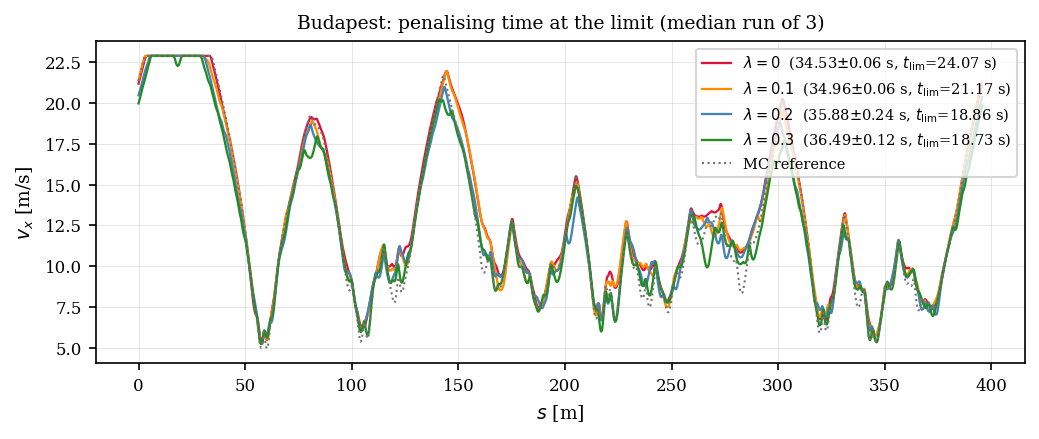

Saved: paper_figs/fig_nondiff_pareto.pdf


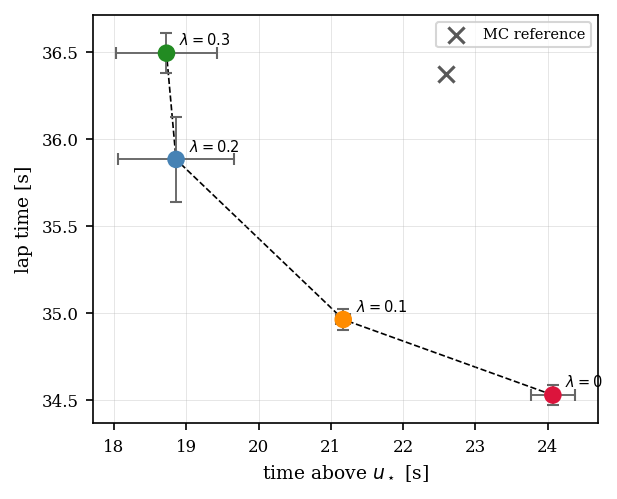

In [24]:
# ===========================================================================
# 6. Figures
# ===========================================================================
COL = {0.0: 'crimson', 0.10: 'darkorange', 0.20: 'steelblue', 0.30: 'forestgreen'}

fig, axv = plt.subplots(figsize=(7.0, 3.0))
for lam in LAMBDAS:
    r_ = nd_results[lam]
    m = r_['median']
    axv.plot(m['s'], m['vx'], color=COL[lam], lw=1.1,
             label=(rf"$\lambda={lam:g}$  ({r_['laptime']:.2f}$\pm$"
                    rf"{r_['laptime_sd']:.2f} s, $t_{{\mathrm{{lim}}}}$="
                    rf"{r_['t_lim']:.2f} s)"))
axv.plot(mc['s'], mc['vx'], color='0.45', lw=1.0, ls=':', label='MC reference')
axv.set_ylabel('$v_x$ [m/s]')
axv.set_xlabel('$s$ [m]')
axv.set_title(f'{CIRCUIT}: penalising time at the limit '
              f'(median run of {N_REPEATS})')
axv.legend(fontsize=7, framealpha=0.8)
axv.grid(True, lw=0.3, alpha=0.5)
plt.tight_layout()
_f = os.path.join(FIG_DIR, 'fig_nondiff_profiles.pdf')
plt.savefig(_f)
print(f"Saved: {_f}")
plt.show()

# Pareto front
fig2, axp = plt.subplots(figsize=(4.2, 3.4))
_x = [nd_results[l]['t_lim'] for l in LAMBDAS]
_y = [nd_results[l]['laptime'] for l in LAMBDAS]
axp.errorbar(_x, _y,
             xerr=[nd_results[l]['t_lim_sd'] for l in LAMBDAS],
             yerr=[nd_results[l]['laptime_sd'] for l in LAMBDAS],
             fmt='none', ecolor='0.4', elinewidth=0.9, capsize=3, zorder=2)
axp.scatter(_x, _y, c=[COL[l] for l in LAMBDAS], s=55, zorder=3)
axp.plot(_x, _y, 'k--', lw=0.8, zorder=1)
for lam, x_, y_ in zip(LAMBDAS, _x, _y):
    axp.annotate(rf'$\lambda={lam:g}$', (x_, y_),
                 textcoords='offset points', xytext=(6, 4), fontsize=7)
axp.scatter([mc['t_lim']], [mc['laptime']], marker='x', c='0.35', s=60,
            zorder=4, label='MC reference')
axp.set_xlabel(r'time above $u_\star$ [s]')
axp.set_ylabel('lap time [s]')
axp.grid(True, lw=0.3, alpha=0.5)
axp.legend(fontsize=7, framealpha=0.8)
plt.tight_layout()
_f = os.path.join(FIG_DIR, 'fig_nondiff_pareto.pdf')
plt.savefig(_f)
print(f"Saved: {_f}")
plt.show()


# Example 2: the fastest line a given controller can track

A raceline is only as fast as the controller that drives it. Here the vehicle is
driven by a **fixed, simple tracking controller**: curvature feed-forward with a
short preview, heading and cross-track feedback (Stanley), and a speed loop on the
planned profile. Its steering actuator is **slow**: first-order lag
$\tau = 0.1$ s and a rate limit of $2$ rad/s. The simulated car uses the same
point-mass envelope as the planner (12 m/s$^2$, $e = 1.5$); when the controller
asks for more lateral acceleration than the envelope allows, the car runs wide.

With this controller the usual planned lines are **not trackable**: the
minimum-curvature line, the lap-time optimum and the point-mass OCP solution all
leave the track even at 80% of their planned speed. Only the centreline, which
keeps 0.6 m from both limits, is trackable at its planned speed.

The cost is the **closed-loop lap time** with a penalty on leaving the track,

$$C(\alpha) = T_{\mathrm{cl}}(\alpha) + W\,A(\alpha), \qquad W = 10\ \mathrm{s/m^2},$$

where $T_{\mathrm{cl}}$ is the lap time of the simulated closed loop and $A$ the
area of the excursion beyond the track limits. A returned line that stays within
the 1 cm tolerance pays a negligible penalty ($W A$ of a few hundredths of a
second), so $W$ has traded essentially no lap time against the excursion; the
table reports the excursion to show this.

$C$ is the output of a simulation with saturations, a rate limit and a
nearest-point search. It is not differentiable, and it has no optimal-control
formulation. Both zeroth-order solvers are used.


In [3]:
# ===========================================================================
# 7. Closed-loop simulator and controller
#
# Kinematic bicycle on the planner's envelope, driven by a fixed tracking
# controller with a slow steering actuator. The controller gains were tuned on
# the minimum-curvature line and the centreline only, never on an optimised line.
# ===========================================================================
import math
from numba import njit

CTRL = dict(L=1.4,                      # wheelbase [m]
            dt=0.005,                   # integration step [s]
            tau=0.10, rate=2.0,         # steering lag [s], rate limit [rad/s]
            dmax=0.7,                   # steering limit [rad]
            k_psi=0.5, k_e=1.0,         # heading / cross-track (Stanley) gains
            k_v=2.0,                    # speed-loop gain [1/s]
            t_prev=0.1)                 # curvature preview [s]
N_MAX = float(reftrack[0, 2] - VEH['w_veh'] / 2)   # 0.6 m, constant corridor
TOL = 0.01                                          # excursion still "on track" [m]


def plan_cl(alpha, si=SI):
    """Planned path and speed profile -- the same chain as profile() -- plus the
    geometry the controller tracks."""
    rl, _, cx, cy, si_idx, tv, s, _, el = create_raceline(
        refline=reftrack[:, :2], normvectors=_nv, alpha=alpha, stepsize_interp=si)
    _, kappa = calc_head_curv_an(coeffs_x=cx, coeffs_y=cy, ind_spls=si_idx, t_spls=tv)
    n = kappa.size
    if n not in _ggv_cache:
        _ggv_cache[n] = np.repeat(np.expand_dims(ggv, 0), n, 0)
    vx = calc_vel_profile(
        ggv=ggv, ax_max_machines=ax_max, v_max=VEH['v_max'], kappa=kappa,
        el_lengths=el, closed=True, filt_window=VEH['fw'],
        dyn_model_exp=VEH['dyn_model_exp'], drag_coeff=VEH['drag_coeff'],
        m_veh=VEH['m_veh'], p_ggv=_ggv_cache[n])
    ax = calc_ax_profile(vx_profile=np.append(vx, vx[0]), el_lengths=el,
                         eq_length_output=False)
    t = calc_t_profile(vx_profile=vx, ax_profile=ax, el_lengths=el)
    m = min(len(rl), len(vx), len(kappa), len(ax))
    # lateral offset of the path from the centreline, for the track-limit check
    i0 = si_idx[:m] % alpha.size
    n_off = (1 - tv[:m]) * alpha[i0] + tv[:m] * alpha[(i0 + 1) % alpha.size]
    return dict(x=rl[:m, 0].copy(), y=rl[:m, 1].copy(), s=s[:m].copy(),
                ltot=float(np.sum(el)), kap=kappa[:m].copy(), v=vx[:m].copy(),
                ax=ax[:m].copy(), n=n_off.copy(), t_plan=float(t[-1]))


@njit
def _interp_wrap(S, F, ltot, s):
    """Linear interpolation of F(S) on a closed lap."""
    s = s % ltot
    j = max(np.searchsorted(S, s) - 1, 0)
    j2 = (j + 1) % S.size
    s2 = S[j2] if j2 > 0 else ltot
    w = (s - S[j]) / (s2 - S[j]) if s2 > S[j] else 0.0
    return F[j] + w * (F[j2] - F[j])


@njit
def _interp_angle(S, F, ltot, s):
    """As _interp_wrap, for an angle: interpolates along the shorter arc."""
    s = s % ltot
    j = max(np.searchsorted(S, s) - 1, 0)
    j2 = (j + 1) % S.size
    s2 = S[j2] if j2 > 0 else ltot
    w = (s - S[j]) / (s2 - S[j]) if s2 > S[j] else 0.0
    return F[j] + w * ((F[j2] - F[j] + math.pi) % (2 * math.pi) - math.pi)


@njit
def simulate(X, Y, S, ltot, KAP, V, AX, NOFF, PSI, vmax, cd, m_veh, nmax,
             L, dt, tau, rate, dmax, k_psi, k_e, k_v, t_prev, amax, e_exp):
    """One flying lap. Returns (lap time, excursion area, max excursion, rms e).

    A lost car (|e| > 3 m) returns 100 s plus the time so far plus the distance
    still to go at 5 m/s, so that failing lines are still ranked by progress.
    """
    N = X.size
    x, y, v = X[0], Y[0], V[0]
    psi = math.atan2(Y[1] - Y[0], X[1] - X[0])
    delta = math.atan(L * KAP[0])
    idx, s_prev, s_done, t = 0, 0.0, 0.0, 0.0
    area, max_exc, e_sq, n_e = 0.0, 0.0, 0.0, 0
    for k in range(int(4.0 * ltot / dt)):
        # nearest point on the path, searched in a window ahead of the last one
        best, bj, bw, e = 1e18, idx, 0.0, 0.0
        for jj in range(-3, 40):
            j = (idx + jj) % N
            j2 = (j + 1) % N
            ux, uy = X[j2] - X[j], Y[j2] - Y[j]
            l2 = ux * ux + uy * uy
            w = ((x - X[j]) * ux + (y - Y[j]) * uy) / l2 if l2 > 0 else 0.0
            w = min(max(w, 0.0), 1.0)
            d2 = (x - X[j] - w * ux) ** 2 + (y - Y[j] - w * uy) ** 2
            if d2 < best:
                best, bj, bw = d2, j, w
                # signed distance to the nearest point (+ = left). The distance to
                # the segment's infinite line would jump when the nearest segment
                # changes, and so would the whole trajectory.
                side = ux * (y - Y[j]) - uy * (x - X[j])
                e = math.sqrt(d2) if side >= 0 else -math.sqrt(d2)
        idx = bj
        j2 = (bj + 1) % N
        s = S[bj] + bw * ((S[j2] if j2 > 0 else ltot) - S[bj])
        # reference heading interpolated along s: the heading of the current
        # segment is piecewise constant and would jump at every segment switch
        psi_r = _interp_angle(S, PSI, ltot, s)
        dpsi = (psi - psi_r + math.pi) % (2 * math.pi) - math.pi
        # progress; the finish-line crossing is interpolated within the step
        ds = s - s_prev
        if ds < -0.5 * ltot:
            ds += ltot
        elif ds > 0.5 * ltot:
            ds -= ltot
        if k > 0 and ds > 0 and s_done + ds >= ltot:
            return (t - dt + dt * (ltot - s_done) / ds, area, max_exc,
                    math.sqrt(e_sq / n_e))
        s_done += ds
        s_prev = s
        # track limits
        # NOFF is positive to the right (OptiLine normals point right), e to the left
        exc = abs(_interp_wrap(S, NOFF, ltot, s) - e) - nmax
        if exc > 0:
            area += exc * v * dt
            max_exc = max(max_exc, exc)
        e_sq += e * e
        n_e += 1
        if abs(e) > 3.0:
            return (100.0 + t + (ltot - s_done) / 5.0, area, max_exc,
                    math.sqrt(e_sq / n_e))
        # steering: previewed curvature feed-forward + heading + cross-track
        kff = _interp_wrap(S, KAP, ltot, s + v * t_prev)
        dcmd = math.atan(L * kff) - k_psi * dpsi - math.atan(k_e * e / (v + 1.0))
        dcmd = min(max(dcmd, -dmax), dmax)
        delta += min(max((dcmd - delta) / tau, -rate), rate) * dt
        # lateral acceleration saturates at the envelope: the car runs wide
        ay = min(max(v * v * math.tan(delta) / L, -amax), amax)
        # longitudinal: planned a_x + speed feedback, within the remaining grip
        drag = cd * v * v / m_veh
        rem = 1.0 - (abs(ay) / amax) ** e_exp
        avail = amax * rem ** (1.0 / e_exp) if rem > 0 else 0.0
        a_t = _interp_wrap(S, AX, ltot, s) + k_v * (_interp_wrap(S, V, ltot, s) - v) + drag
        a_t = min(max(a_t, -avail), avail)
        psi += ay / max(v, 0.1) * dt
        v = min(max(v + (a_t - drag) * dt, 0.1), vmax)
        x += v * math.cos(psi) * dt
        y += v * math.sin(psi) * dt
        t += dt
    return 1e3, area, max_exc, math.sqrt(e_sq / max(n_e, 1))


def closed_loop(alpha=None, beta=1.0, p=None):
    """Drive one lap of alpha with the controller tracking beta x the planned speed."""
    p = plan_cl(alpha) if p is None else p
    c = CTRL
    # heading at each vertex: the mean of its two segment headings
    seg = np.arctan2(np.roll(p['y'], -1) - p['y'], np.roll(p['x'], -1) - p['x'])
    psi_v = np.roll(seg, 1) + 0.5 * ((seg - np.roll(seg, 1) + np.pi) % (2 * np.pi) - np.pi)
    T, area, mexc, erms = simulate(
        p['x'], p['y'], p['s'], p['ltot'], p['kap'], beta * p['v'],
        beta ** 2 * p['ax'], p['n'], psi_v, VEH['v_max'], VEH['drag_coeff'],
        VEH['m_veh'], N_MAX, c['L'], c['dt'], c['tau'], c['rate'], c['dmax'],
        c['k_psi'], c['k_e'], c['k_v'], c['t_prev'], A_MAX, VEH['dyn_model_exp'])
    return dict(t_plan=p['t_plan'], t_cl=T, area=area, max_exc=mexc, e_rms=erms,
                on_track=bool(T < 99 and mexc <= TOL))


W_TRACK = 10.0      # [s/m^2] weight on the excursion area beyond the track limits


def track_cost(alpha):
    """Closed-loop lap time plus a weighted penalty on leaving the track.

    Module-level, so the solver can pickle it and evaluate in worker processes.
    """
    r = closed_loop(alpha)
    return r['t_cl'] + W_TRACK * r['area']


_r = closed_loop(alpha_mc)                     # compiles the simulator
assert abs(_r['t_plan'] - mc['laptime']) < 1e-9, "plan_cl and profile() disagree"
print(f"MC through the closed loop: planned {_r['t_plan']:.3f} s, "
      f"closed-loop {_r['t_cl']:.3f} s, max excursion {100 * _r['max_exc']:.1f} cm")


MC through the closed loop: planned 36.375 s, closed-loop 36.178 s, max excursion 3.7 cm


In [4]:
# ===========================================================================
# 8. Trackability of the usual lines
#
# Each line is driven at beta x its planned speed; beta_max is the largest scale,
# on a 0.005 grid from 1.00 down to 0.80, at which the car stays on track.
# The lap-time optimum is a plain ZORM run on the lap time (the default cost); the
# point-mass OCP is run exactly as in Experiments.ipynb (full centreline, 1250
# cells) and its own path and speed profile are handed to the controller.
# ===========================================================================
from OptiLine.solvers import PointMassOCP

BETAS = np.round(np.arange(1.0, 0.7999, -0.005), 3)


def beta_max(p):
    """Largest speed scale at which the controller keeps the planned line p on track."""
    for b in BETAS:
        r = closed_loop(beta=b, p=p)
        if r['on_track']:
            return b, r
    return None, closed_loop(p=p)


def pm_plan():
    """PointMassOCP solution in the format closed_loop() takes."""
    full = subsample_reftrack(
        np.loadtxt(TRACK, comments='#', delimiter=',')[:, :4], step=1, mode='arc')
    pm = PointMassOCP(full, ggv, w_veh=VEH['w_veh'], v_max=VEH['v_max'],
                      ax_max_machines=ax_max, dyn_model_exp=VEH['dyn_model_exp'])
    pm.solve(mesh=max(0.05, pm.track_length / 1250))
    if not pm.solver_info['success']:
        raise RuntimeError(f"PointMassOCP did not converge ({pm.solver_info['status']})")
    # the returned lap repeats its first point; drop it so no segment has zero length
    k = slice(0, -1)
    return dict(x=pm.raceline[k, 0].copy(), y=pm.raceline[k, 1].copy(),
                s=pm.s[k].copy(), ltot=float(pm.s[-1]), kap=pm.kappa[k].copy(),
                v=pm.vx_profile[k].copy(), ax=pm.ax_profile[k].copy(),
                n=pm.alpha[k].copy(), t_plan=pm.laptime)


t0 = time.time()
_lt = build_bba(n_iter=500)
alpha_lapopt, _ = _lt.find_alpha(solver='ZO', verbose=False)
print(f"lap-time optimum (ZORM, 500 iterations): {time.time() - t0:.0f}s")
t0 = time.time()
p_pm = pm_plan()
print(f"point-mass OCP: {p_pm['t_plan']:.3f} s  ({time.time() - t0:.0f}s)")

ref_plans = {'MC': plan_cl(alpha_mc),
             'Centreline': plan_cl(np.zeros_like(alpha_mc)),
             'Lap-time optimum': plan_cl(alpha_lapopt),
             'PM-OCP': p_pm}
track_ref = {}
for name, p in ref_plans.items():
    b, r = beta_max(p)
    track_ref[name] = dict(beta=b, **r)
    print(f"  {name:17s} planned {r['t_plan']:.3f} s   " +
          (f"trackable at beta {b:.3f}: closed-loop {r['t_cl']:.3f} s"
           if b is not None else f"not trackable at beta >= {BETAS[-1]:.2f}"))


lap-time optimum (ZORM, 500 iterations): 70s
Number of mesh points: 1250

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Total time to complete the track: 32.79 seconds
point-mass OCP: 32.793 s  (44s)
  MC                planned 36.375 s   not trackable at beta >= 0.80
  Centreline        planned 37.644 s   trackable at beta 1.000: closed-loop 37.573 s
  Lap-time optimum  planned 34.128 s   not trackable at beta >= 0.80
  PM-OCP            planned 32.793 s   not trackable at beta >= 0.80


In [5]:
# ===========================================================================
# 9. ZORM and CMA-ES: the fastest line this controller keeps on track
#
# Warm start from the minimum-curvature line, which is itself untrackable.
# ZORM: the blackbox settings of section 1 with 1000 iterations.
# CMA-ES: 1000 generations of 12 candidates.
# ===========================================================================
CL_ITER = 1000
CL_SOLVERS = {'BBA-ZO': ('ZO', {}),
              'BBA-CMA': ('CMA', dict(sigma=0.03, popsize=12))}


from threadpoolctl import threadpool_limits
_blas = threadpool_limits(1)

cl_res = {}
for tag, (solver, kw) in CL_SOLVERS.items():
    runs = []
    for q in range(N_REPEATS):
        t0 = time.time()
        bba = build_bba(cost_fn=track_cost, n_iter=CL_ITER)
        alpha, hist = bba.find_alpha(solver=solver, verbose=False, **kw)
        r = closed_loop(alpha)
        runs.append(dict(alpha=alpha, hist=hist, **r))
        print(f"  {tag:7s} run {q + 1}/{N_REPEATS}: planned {r['t_plan']:.3f} s   "
              f"closed-loop {r['t_cl']:.3f} s   max excursion {100 * r['max_exc']:.2f} cm"
              f"   area {r['area']:.4f} m^2   ({time.time() - t0:.0f}s)", flush=True)
    cl_res[tag] = dict(t_plan=agg([r['t_plan'] for r in runs]),
                       t_cl=agg([r['t_cl'] for r in runs]),
                       max_exc=max(r['max_exc'] for r in runs),
                       n_on_track=sum(r['on_track'] for r in runs),
                       median=runs[median_idx([r['t_cl'] for r in runs])], runs=runs)
    c = cl_res[tag]
    print(f"    => planned {c['t_plan'][0]:.3f}+-{c['t_plan'][1]:.3f} s   closed-loop "
          f"{c['t_cl'][0]:.3f}+-{c['t_cl'][1]:.3f} s   worst excursion "
          f"{100 * c['max_exc']:.2f} cm   ({c['n_on_track']}/{N_REPEATS} on track)")
_blas.restore_original_limits()

  BBA-ZO  run 1/3: planned 35.670 s   closed-loop 35.327 s   max excursion 0.24 cm   area 0.0013 m^2   (189s)
  BBA-ZO  run 2/3: planned 35.311 s   closed-loop 35.055 s   max excursion 0.05 cm   area 0.0002 m^2   (193s)
  BBA-ZO  run 3/3: planned 35.871 s   closed-loop 35.403 s   max excursion 0.41 cm   area 0.0026 m^2   (186s)
    => planned 35.617+-0.283 s   closed-loop 35.262+-0.183 s   worst excursion 0.41 cm   (3/3 on track)
  BBA-CMA run 1/3: planned 34.673 s   closed-loop 34.182 s   max excursion 0.00 cm   area 0.0000 m^2   (148s)
  BBA-CMA run 2/3: planned 34.524 s   closed-loop 34.170 s   max excursion 0.15 cm   area 0.0003 m^2   (149s)
  BBA-CMA run 3/3: planned 34.394 s   closed-loop 34.058 s   max excursion 0.00 cm   area 0.0000 m^2   (148s)
    => planned 34.530+-0.140 s   closed-loop 34.137+-0.068 s   worst excursion 0.15 cm   (3/3 on track)


In [6]:
# ===========================================================================
# 10. LaTeX table
#
# The excursion column is at the planned speed (beta = 1) for every line, so the
# untrackable lines show how far they leave the track.
# ===========================================================================
exc_full = {}
for name, p in ref_plans.items():
    r = closed_loop(p=p)
    exc_full[name] = "lost" if r['t_cl'] > 99 else f"{100 * r['max_exc']:.1f}"

print(r"% ===== Closed-loop trackability =====")
print(r"\begin{table}[t]")
print(r"  \centering")
print(r"  \caption{Lines driven by a fixed tracking controller with a slow steering "
      r"actuator on Budapest. $\beta_{\max}$ is the largest fraction of the planned "
      r"speed at which the car stays on track, and the closed-loop lap is driven at "
      r"that speed. The excursion is the largest distance beyond the track limits "
      r"at the planned speed ($\beta = 1$). BBA entries are the mean over "
      rf"{N_REPEATS} runs $\pm$ one sample standard deviation; their excursion is "
      r"the largest over the runs.}")
print(r"  \label{tab:closedloop}")
print(r"  \begin{tabular}{lcccc}")
print(r"    \toprule")
print(r"    Line & Planned lap (s) & $\beta_{\max}$ & Closed-loop lap (s)"
      r" & Excursion (cm) \\")
print(r"    \midrule")
for name, r in track_ref.items():
    if r['beta'] is None:
        print(f"    {name} & {r['t_plan']:.2f} & $<{BETAS[-1]:.2f}$ & ---"
              f" & {exc_full[name]} \\\\")
    else:
        print(f"    {name} & {r['t_plan']:.2f} & {r['beta']:.3f} & {r['t_cl']:.2f}"
              f" & {exc_full[name]} \\\\")
for tag, c in cl_res.items():
    _b = "1.000" if c['n_on_track'] == N_REPEATS else "---"
    print(f"    {tag} & {pm(*c['t_plan'])} & {_b} & {pm(*c['t_cl'])}"
          f" & {100 * c['max_exc']:.1f} \\\\")
print(r"    \bottomrule")
print(r"  \end{tabular}")
print(r"\end{table}")

% ===== Closed-loop trackability =====
\begin{table}[t]
  \centering
  \caption{Lines driven by a fixed tracking controller with a slow steering actuator on Budapest. $\beta_{\max}$ is the largest fraction of the planned speed at which the car stays on track, and the closed-loop lap is driven at that speed. The excursion is the largest distance beyond the track limits at the planned speed ($\beta = 1$). BBA entries are the mean over 3 runs $\pm$ one sample standard deviation; their excursion is the largest over the runs.}
  \label{tab:closedloop}
  \begin{tabular}{lcccc}
    \toprule
    Line & Planned lap (s) & $\beta_{\max}$ & Closed-loop lap (s) & Excursion (cm) \\
    \midrule
    MC & 36.38 & $<0.80$ & --- & 3.7 \\
    Centreline & 37.64 & 1.000 & 37.57 & 0.0 \\
    Lap-time optimum & 34.13 & $<0.80$ & --- & lost \\
    PM-OCP & 32.79 & $<0.80$ & --- & 8.8 \\
    BBA-ZO & $35.62 \pm 0.28$ & 1.000 & $35.26 \pm 0.18$ & 0.4 \\
    BBA-CMA & $34.53 \pm 0.14$ & 1.000 & $34.14 \pm 0.07$

Saved: paper_figs/fig_closedloop_profiles.pdf


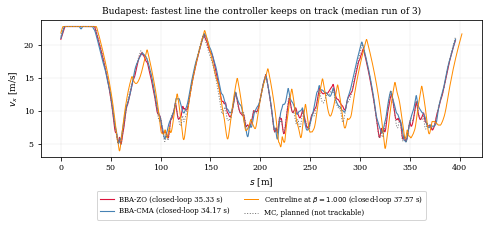

In [7]:
# ===========================================================================
# 11. Figure: planned speed of each line at the speed the controller can drive it
# ===========================================================================
CL_COL = {'BBA-ZO': 'crimson', 'BBA-CMA': 'steelblue'}

fig, axv = plt.subplots(figsize=(7.0, 3.4))
for tag, c in cl_res.items():
    _p = plan_cl(c['median']['alpha'])
    axv.plot(_p['s'], _p['v'], color=CL_COL[tag], lw=1.1,
             label=f"{tag} (closed-loop {c['median']['t_cl']:.2f} s)")
_c = track_ref['Centreline']
if _c['beta'] is not None:
    _pc = ref_plans['Centreline']
    axv.plot(_pc['s'], _c['beta'] * _pc['v'], color='darkorange', lw=1.0,
             label=rf"Centreline at $\beta={_c['beta']:.3f}$ "
                   f"(closed-loop {_c['t_cl']:.2f} s)")
_pm = ref_plans['MC']
axv.plot(_pm['s'], _pm['v'], color='0.45', lw=1.0, ls=':',
         label='MC, planned (not trackable)')
axv.set_ylabel('$v_x$ [m/s]')
axv.set_xlabel('$s$ [m]')
axv.set_title(f'{CIRCUIT}: fastest line the controller keeps on track '
              f'(median run of {N_REPEATS})')
# below the axes: inside, it covers the fast sections
axv.legend(fontsize=7, framealpha=0.8, ncol=2, loc='upper center',
           bbox_to_anchor=(0.5, -0.22))
axv.grid(True, lw=0.3, alpha=0.5)
plt.tight_layout()
_f = os.path.join(FIG_DIR, 'fig_closedloop_profiles.pdf')
plt.savefig(_f)
print(f"Saved: {_f}")
plt.show()


In [8]:
# ===========================================================================
# 12. Animations (1/2): the simulator of section 7, logging the trajectory
#
# Same arithmetic as simulate(); the assert below checks that both return the
# same lap time, area and excursion to the last bit.
# ===========================================================================
@njit
def simulate_log(X, Y, S, ltot, KAP, V, AX, NOFF, PSI, vmax, cd, m_veh, nmax,
                 L, dt, tau, rate, dmax, k_psi, k_e, k_v, t_prev, amax, e_exp):
    """simulate(), also returning x, y, heading, speed and excursion per step."""
    K = int(4.0 * ltot / dt)
    LX, LY, LPSI = np.empty(K), np.empty(K), np.empty(K)
    LV, LEXC, LS = np.empty(K), np.empty(K), np.empty(K)
    nlog = 0
    N = X.size
    x, y, v = X[0], Y[0], V[0]
    psi = math.atan2(Y[1] - Y[0], X[1] - X[0])
    delta = math.atan(L * KAP[0])
    idx, s_prev, s_done, t = 0, 0.0, 0.0, 0.0
    area, max_exc, e_sq, n_e = 0.0, 0.0, 0.0, 0
    T = 1e3
    for k in range(K):
        best, bj, bw, e = 1e18, idx, 0.0, 0.0
        for jj in range(-3, 40):
            j = (idx + jj) % N
            j2 = (j + 1) % N
            ux, uy = X[j2] - X[j], Y[j2] - Y[j]
            l2 = ux * ux + uy * uy
            w = ((x - X[j]) * ux + (y - Y[j]) * uy) / l2 if l2 > 0 else 0.0
            w = min(max(w, 0.0), 1.0)
            d2 = (x - X[j] - w * ux) ** 2 + (y - Y[j] - w * uy) ** 2
            if d2 < best:
                best, bj, bw = d2, j, w
                side = ux * (y - Y[j]) - uy * (x - X[j])
                e = math.sqrt(d2) if side >= 0 else -math.sqrt(d2)
        idx = bj
        j2 = (bj + 1) % N
        s = S[bj] + bw * ((S[j2] if j2 > 0 else ltot) - S[bj])
        psi_r = _interp_angle(S, PSI, ltot, s)
        dpsi = (psi - psi_r + math.pi) % (2 * math.pi) - math.pi
        ds = s - s_prev
        if ds < -0.5 * ltot:
            ds += ltot
        elif ds > 0.5 * ltot:
            ds -= ltot
        if k > 0 and ds > 0 and s_done + ds >= ltot:
            T = t - dt + dt * (ltot - s_done) / ds
            break
        s_done += ds
        s_prev = s
        exc = abs(_interp_wrap(S, NOFF, ltot, s) - e) - nmax
        if exc > 0:
            area += exc * v * dt
            max_exc = max(max_exc, exc)
        e_sq += e * e
        n_e += 1
        LX[nlog], LY[nlog], LPSI[nlog] = x, y, psi
        LV[nlog], LEXC[nlog], LS[nlog] = v, exc, s
        nlog += 1
        if abs(e) > 3.0:
            T = 100.0 + t + (ltot - s_done) / 5.0
            break
        kff = _interp_wrap(S, KAP, ltot, s + v * t_prev)
        dcmd = math.atan(L * kff) - k_psi * dpsi - math.atan(k_e * e / (v + 1.0))
        dcmd = min(max(dcmd, -dmax), dmax)
        delta += min(max((dcmd - delta) / tau, -rate), rate) * dt
        ay = min(max(v * v * math.tan(delta) / L, -amax), amax)
        drag = cd * v * v / m_veh
        rem = 1.0 - (abs(ay) / amax) ** e_exp
        avail = amax * rem ** (1.0 / e_exp) if rem > 0 else 0.0
        a_t = _interp_wrap(S, AX, ltot, s) + k_v * (_interp_wrap(S, V, ltot, s) - v) + drag
        a_t = min(max(a_t, -avail), avail)
        psi += ay / max(v, 0.1) * dt
        v = min(max(v + (a_t - drag) * dt, 0.1), vmax)
        x += v * math.cos(psi) * dt
        y += v * math.sin(psi) * dt
        t += dt
    erms = math.sqrt(e_sq / max(n_e, 1))
    return (T, area, max_exc, erms, LX[:nlog], LY[:nlog], LPSI[:nlog],
            LV[:nlog], LEXC[:nlog], LS[:nlog])


def drive(p, beta=1.0):
    """Closed-loop lap of the planned line p with its trajectory, as closed_loop()."""
    c = CTRL
    seg = np.arctan2(np.roll(p['y'], -1) - p['y'], np.roll(p['x'], -1) - p['x'])
    psi_v = np.roll(seg, 1) + 0.5 * ((seg - np.roll(seg, 1) + np.pi) % (2 * np.pi) - np.pi)
    out = simulate_log(
        p['x'], p['y'], p['s'], p['ltot'], p['kap'], beta * p['v'],
        beta ** 2 * p['ax'], p['n'], psi_v, VEH['v_max'], VEH['drag_coeff'],
        VEH['m_veh'], N_MAX, c['L'], c['dt'], c['tau'], c['rate'], c['dmax'],
        c['k_psi'], c['k_e'], c['k_v'], c['t_prev'], A_MAX, VEH['dyn_model_exp'])
    r = closed_loop(beta=beta, p=p)
    assert out[:3] == (r['t_cl'], r['area'], r['max_exc']), "logger differs from simulate()"
    keys = ('x', 'y', 'psi', 'v', 'exc', 's')
    return dict(t_plan=p['t_plan'], t_cl=out[0], max_exc=out[2],
                lost=out[0] > 99, **dict(zip(keys, out[4:])))


# every line at its planned speed: the reference lines and the median BBA runs
anim_plans = dict(ref_plans)
for tag, c in cl_res.items():
    anim_plans[tag] = plan_cl(c['median']['alpha'])
drives = {name: drive(p) for name, p in anim_plans.items()}
for name, d in drives.items():
    print(f"  {name:17s} closed-loop {d['t_cl']:.3f} s   max excursion "
          f"{100 * d['max_exc']:.1f} cm" + ("   LOST" if d['lost'] else ""))

  MC                closed-loop 36.178 s   max excursion 3.7 cm
  Centreline        closed-loop 37.573 s   max excursion 0.0 cm
  Lap-time optimum  closed-loop 136.575 s   max excursion 201.1 cm   LOST
  PM-OCP            closed-loop 33.081 s   max excursion 8.8 cm
  BBA-ZO            closed-loop 35.327 s   max excursion 0.2 cm
  BBA-CMA           closed-loop 34.170 s   max excursion 0.1 cm


In [ ]:
# ===========================================================================
# 12. Animations : one video per line, driven at its planned speed
#
# Left: the whole track, with the points where the car was beyond the limits.
# Right: a window that follows the car and the excursion beyond the limits along
# the lap (each video on its own scale).
# The track-limit check uses the planners' width (1.0 m) around the simulated point.
# The car is drawn as a 0.8 m x 2.0 m marker centred on that point (0.1 m margin on
# each side); the body footprint in corners is not modelled, as in the planners.
# ===========================================================================
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.patches import Polygon

ANIM_DIR = os.path.join(FIG_DIR, 'animations')
os.makedirs(ANIM_DIR, exist_ok=True)
FPS = 25                     # real time: one frame every 0.04 s of the lap
ZOOM = 6.0                   # half-size of the following window [m]
CAR_L, CAR_W = 2.0, 0.8       # drawn marker [m]
CAR_REAR = CAR_L / 2          # marker centred on the simulated point

# track edges, built with the same spline and normals as every planned line
_edges = []
for _a in (reftrack[:, 2], -reftrack[:, 3]):
    _rl = create_raceline(refline=reftrack[:, :2], normvectors=_nv, alpha=_a,
                          stepsize_interp=SI)[0]
    _edges.append(np.vstack((_rl, _rl[:1])))


def car_outline(x, y, psi):
    c, s = math.cos(psi), math.sin(psi)
    front, rear = CAR_L - CAR_REAR, -CAR_REAR
    pts = np.array([[front, CAR_W / 2], [rear, CAR_W / 2],
                    [rear, -CAR_W / 2], [front, -CAR_W / 2]])
    return np.column_stack((x + c * pts[:, 0] - s * pts[:, 1],
                            y + s * pts[:, 0] + c * pts[:, 1]))


def animate(name, d, p, fname):
    k_last = d['x'].size - 1
    # real-time frames, then the last state held for 2 s
    k_frames = np.append(np.arange(0, k_last, int(round(1 / (FPS * CTRL['dt'])))),
                         np.full(2 * FPS, k_last))
    off = d['exc'] > TOL
    exc_cm = 100 * np.maximum(d['exc'], 0.0)
    # distance along the lap; the start projects onto either end of the closed path
    s_lap = np.unwrap(d['s'], period=p['ltot'])
    s_lap -= p['ltot'] * np.round(s_lap[0] / p['ltot'])

    fig = plt.figure(figsize=(10.0, 5.2))
    gs = fig.add_gridspec(2, 2, width_ratios=(1.15, 1.0), height_ratios=(2.2, 1.0))
    ax_t, ax_z, ax_e = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), \
        fig.add_subplot(gs[1, 1])
    for ax in (ax_t, ax_z):
        for ed in _edges:
            ax.plot(ed[:, 0], ed[:, 1], color='0.2', lw=0.8)
        ax.plot(np.append(p['x'], p['x'][0]), np.append(p['y'], p['y'][0]),
                color='steelblue', lw=0.8, ls='--', label='planned line')
        ax.set_aspect('equal')
        ax.set_xticks([]); ax.set_yticks([])
    ax_t.set_title(f"{name}: planned {d['t_plan']:.2f} s, driven at planned speed")
    off_pts, = ax_t.plot([], [], '.', color='crimson', ms=3, label='beyond the limits')
    car_dot, = ax_t.plot([], [], 'o', color='k', ms=4)
    ax_t.legend(loc='lower right', fontsize=7, framealpha=0.8)
    trail, = ax_z.plot([], [], color='k', lw=0.8)
    body = Polygon(car_outline(d['x'][0], d['y'][0], d['psi'][0]), closed=True,
                   fc='0.6', ec='k', lw=0.8)
    ax_z.add_patch(body)
    info = ax_z.text(0.02, 0.97, '', transform=ax_z.transAxes, va='top', fontsize=8,
                     bbox=dict(fc='w', ec='none', alpha=0.8))
    ax_e.set_xlim(0, p['ltot'])
    ax_e.set_ylim(0, max(2.0, 1.15 * exc_cm.max()))   # own scale: 0 cm to 3 m
    ax_e.axhline(100 * TOL, color='0.5', lw=0.6, ls=':')
    ax_e.set_xlabel('$s$ [m]'); ax_e.set_ylabel('excursion [cm]')
    ax_e.grid(True, lw=0.3, alpha=0.5)
    exc_line, = ax_e.plot([], [], color='crimson', lw=0.9)
    plt.tight_layout()

    def update(k):
        sel = np.flatnonzero(off[:k + 1])
        off_pts.set_data(d['x'][sel], d['y'][sel])
        car_dot.set_data([d['x'][k]], [d['y'][k]])
        k0 = max(0, k - int(1.5 / CTRL['dt']))
        trail.set_data(d['x'][k0:k + 1], d['y'][k0:k + 1])
        body.set_xy(car_outline(d['x'][k], d['y'][k], d['psi'][k]))
        body.set_facecolor('crimson' if off[k] else '0.6')
        ax_z.set_xlim(d['x'][k] - ZOOM, d['x'][k] + ZOOM)
        ax_z.set_ylim(d['y'][k] - 0.6 * ZOOM, d['y'][k] + 0.6 * ZOOM)
        exc_line.set_data(s_lap[:k + 1], exc_cm[:k + 1])
        info.set_text(f"t = {k * CTRL['dt']:5.2f} s   v = {d['v'][k]:5.2f} m/s\n"
                      f"excursion {exc_cm[k]:4.1f} cm   max so far "
                      f"{exc_cm[:k + 1].max():4.1f} cm" +
                      ("\nLOST: more than 3 m from the line" if d['lost'] and k == k_last
                       else ""))
        return off_pts, car_dot, trail, body, info, exc_line

    FuncAnimation(fig, update, frames=k_frames, blit=False).save(
        fname, writer=FFMpegWriter(fps=FPS, bitrate=2400))
    plt.close(fig)


for name, d in drives.items():
    t0 = time.time()
    _f = os.path.join(ANIM_DIR, f"closedloop_{name.replace(' ', '_').replace('-', '_')}.mp4")
    animate(name, d, anim_plans[name], _f)
    print(f"Saved: {_f}  ({time.time() - t0:.0f}s)", flush=True)

Saved: paper_figs/animations/closedloop_MC.mp4  (95s)
Saved: paper_figs/animations/closedloop_Centreline.mp4  (104s)
Saved: paper_figs/animations/closedloop_Lap_time_optimum.mp4  (92s)
Saved: paper_figs/animations/closedloop_PM_OCP.mp4  (102s)
Saved: paper_figs/animations/closedloop_BBA_ZO.mp4  (111s)
Saved: paper_figs/animations/closedloop_BBA_CMA.mp4  (101s)
